# Real I₁ / I₂ in Colab: Get the Data, Check It, Recover the Phase
**Colin Casey** · [Dispersion-Assisted-GS-Phase-Recovery](https://github.com/ColinsCoding/Dispersion-Assisted-GS-Phase-Recovery) · ECE 279AS (Jalali Lab)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ColinsCoding/Dispersion-Assisted-GS-Phase-Recovery/blob/main/notebooks/colab_get_I1_I2.ipynb)

The simulator works on synthetic data. This notebook closes the loop on **real** measurements:

1. **What counts as a valid I₁/I₂ pair.** Not every pair of traces is one.
2. **Three ways to get data after leaving the lab.**
3. **Colab setup:** clone the repo, then upload files or read them from Google Drive.
4. **A universal loader** for `.npy / .npz / .mat (incl. v7.3) / .csv / .txt` and scope exports.
5. **Validation:** energy, alignment, a convergence check, and a **null test** that catches traces that aren't really a pair.
6. **Physical units**, and a sweep showing **when real data is recoverable at all**.
7. **Run TD-GS** (`dgs.gs_core.retrieve_phase`, Solli–Gupta–Jalali APL 2009) and plot the result.
8. **A self-test** that pushes synthetic files through the exact same path, so a failure on real data can't be blamed on the code.

---
## 1. What a valid I₁ / I₂ pair is
TD-GS assumes both traces are **the same optical field**, measured after two **different, known** amounts of dispersion:
$$I_k(t) = \left|\mathcal F^{-1}\{\tilde E(\nu)\,e^{i\pi D_k\nu^2}\}\right|^2,\qquad k=1,2.$$

| Requirement | Why | How to check |
|---|---|---|
| Same pulse or data pattern in both arms | GS searches for one field consistent with both | Split one source with a coupler, or use a repeating pattern such as a PRBS |
| **Known** D₁ ≠ D₂ | They set the transfer functions | Fiber spool spec (ps/nm) or measured group delay |
| Same sample rate and time base | The algorithm compares sample by sample | Scope settings |
| Aligned in time | Arm lengths differ, so traces are offset | Cross-correlation (Section 5) |
| Linear detection, not saturated | GS uses √I | Peak below full scale; dark level subtracted |
| Detector bandwidth ≥ signal bandwidth | Low-pass filtering breaks the forward model | See `Eye_Diagrams_Dispersion_Phase_Retrieval_50MHz.ipynb` |

**Energy is conserved by dispersion**, so after dark-level subtraction ∑I₁ ≈ ∑I₂ (up to arm loss). That gives a cheap first check.

## 2. Getting data after leaving the lab
**A. Ask the lab (best).** One calibration run is enough. The request template in `REQUESTING_DATA.md` and the draft in `email_to_callen.txt` already list the formats. Ask specifically for:
* `I1`, `I2` as arrays, **plus** D₁, D₂ (ps/nm or ps²), center wavelength, sample rate, and detector/scope bandwidth;
* a run with a **known input** (e.g., QPSK with known symbols) so the recovered phase can be scored.

**B. Public data (for testing the loader only).** Dryad [10.5061/dryad.2h7d2](https://doi.org/10.5061/dryad.2h7d2), *Data from: Optical data compression in time stretch imaging* (Chen, Mahjoubfar, Jalali; PLOS ONE 2015). It's real time-stretch data from the Jalali lab, but it records **imaging scans**, with linear and warped (nonlinear, fiber-Bragg-grating) dispersion. It is **not** one field measured at two dispersions, so it can't validate phase retrieval. Section 5 shows the validator rejecting the pair extracted from it (`data/raw/raw_traces.npz`) when that file is present.

**C. Make your own, in space instead of time.** Photograph a laser beam at two distances from a phase object. By space–time duality (Kolner, IEEE JQE 1994), propagation distance plays the role of dispersion. The two-plane version with a camera loader is in `Fall2026/Spatial_Phase_Retrieval_Two_Plane_CUDA.ipynb`. Hardware costs about $100–300, with no lab needed.

---
## 3. Setup
In Colab, this clones the repo and makes `dgs` importable. Locally, it finds the repo from the notebook's folder. Set `USE_DRIVE = True` to read or write files in Google Drive (you'll be asked to authorize).

In [1]:
import sys, os, io, json, subprocess
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules
USE_DRIVE = False
REPO_URL = 'https://github.com/ColinsCoding/Dispersion-Assisted-GS-Phase-Recovery.git'

if IN_COLAB:
    REPO = Path('/content/Dispersion-Assisted-GS-Phase-Recovery')
    if not REPO.exists():
        subprocess.run(['git', 'clone', '--depth', '1', REPO_URL, str(REPO)], check=True)
    if USE_DRIVE:
        from google.colab import drive
        drive.mount('/content/drive')
    WORK = Path('/content/drive/MyDrive/tdgs_data') if USE_DRIVE else Path('/content/tdgs_data')
else:
    REPO = Path.cwd().resolve()
    while not (REPO/'dgs'/'gs_core.py').exists() and REPO != REPO.parent:
        REPO = REPO.parent
    WORK = REPO/'data'/'colab_uploads'
sys.path.insert(0, str(REPO))
WORK.mkdir(parents=True, exist_ok=True)

import numpy as np
import matplotlib.pyplot as plt
from scipy import io as spio
from dgs import gs_core

print('Colab' if IN_COLAB else 'local Jupyter', '| repo:', REPO, '| data folder:', WORK)

local Jupyter | repo: D:\Summer2026\Dispersion-Assisted-GS-Phase-Recovery | data folder: D:\Summer2026\Dispersion-Assisted-GS-Phase-Recovery\data\colab_uploads


---
## 4. Universal loader
`load_pair(files)` accepts:
* **one file** holding both traces: `.npz`/`.mat` with variables such as `I1`/`I2`, `i1`/`i2`, `ch1`/`ch2`; a 2-column array; or a CSV with a time column plus two channels;
* **two files**, one per arm (scope exports are usually one CSV per channel).

A `metadata.json` next to the data (`D1`, `D2`, units, sample rate, wavelength) is picked up automatically. The template is in Section 6.

In [2]:
NAMES = [('I1', 'I2'), ('i1', 'i2'), ('ch1', 'ch2'), ('CH1', 'CH2'), ('trace1', 'trace2'), ('channel1', 'channel2')]

def _read_mat(path):
    try:
        d = spio.loadmat(path, squeeze_me=True)
        return {k: np.asarray(v) for k, v in d.items() if not k.startswith('__')}
    except NotImplementedError:                          # MATLAB v7.3 = HDF5
        import h5py
        with h5py.File(path, 'r') as f:
            return {k: np.asarray(f[k]).squeeze() for k in f.keys() if isinstance(f[k], h5py.Dataset)}

def _read_table(path):
    '''CSV/TXT with any number of non-numeric header lines (typical scope export).'''
    lines = Path(path).read_text(errors='ignore').splitlines()
    start = next(i for i, ln in enumerate(lines)
                 if ln.strip() and all(_isnum(x) for x in ln.replace(';', ',').replace('\t', ',').split(',') if x.strip()))
    delim = ',' if ',' in lines[start] else None
    return np.loadtxt(io.StringIO('\n'.join(lines[start:])), delimiter=delim, ndmin=2)

def _isnum(s):
    try:
        float(s); return True
    except ValueError:
        return False

def _read_any(path):
    path = Path(path); ext = path.suffix.lower()
    if ext == '.npy':
        return {'array': np.load(path)}
    if ext == '.npz':
        d = np.load(path); return {k: d[k] for k in d.files}
    if ext == '.mat':
        return _read_mat(path)
    if ext in ('.csv', '.txt', '.dat'):
        return {'array': _read_table(path)}
    raise ValueError(f'unsupported file type: {path.name}')

def _one_trace(d):
    '''Pull a single intensity trace from a file that holds one channel (last column = signal).'''
    a = np.asarray(d.get('array', next(iter(d.values()))), float)
    return a[:, -1] if a.ndim == 2 else a.ravel()

def load_pair(files):
    files = [Path(f) for f in files]
    if len(files) == 2:
        return _one_trace(_read_any(files[0])), _one_trace(_read_any(files[1])), f'{files[0].name} + {files[1].name}'
    d = _read_any(files[0])
    for a, b in NAMES:
        if a in d and b in d:
            return np.asarray(d[a], float).ravel(), np.asarray(d[b], float).ravel(), f'{files[0].name}:{a}/{b}'
    arr = np.asarray(d.get('array', next(iter(d.values()))), float)
    if arr.ndim == 2 and arr.shape[1] >= 2:
        cols = arr[:, -2:]                                # last two columns = the two arms (first may be time)
        return cols[:, 0], cols[:, 1], f'{files[0].name}: last two columns'
    raise ValueError(f'{files[0].name}: could not find two traces. Name them I1/I2 or pass two files.')

def load_metadata(folder):
    p = Path(folder)/'metadata.json'
    return json.loads(p.read_text()) if p.exists() else None

### Put your files in
* **Colab:** run the next cell and pick files (one file with both arms, or two files, plus an optional `metadata.json`).
* **Local:** copy the files into `data/colab_uploads/`.

If no files are provided, the notebook falls back to the **self-test data** from Section 8, so every cell still runs.

In [3]:
if IN_COLAB and not USE_DRIVE:
    from google.colab import files
    uploaded = files.upload()                      # opens a file picker
    for name, content in uploaded.items():
        (WORK/name).write_bytes(content)

DATA_FILES = sorted(p for p in WORK.iterdir() if p.suffix.lower() in ('.npy', '.npz', '.mat', '.csv', '.txt', '.dat'))
print('data files found:', [p.name for p in DATA_FILES] or 'none (the self-test data will be used)')

data files found: none (the self-test data will be used)


---
## 5. Validation
| Check | Pass condition |
|---|---|
| finite, same length | no NaN/Inf; lengths match, or are trimmed to match |
| dark level | subtract the **measured** dark level from `metadata.json` (`"dark": [d1, d2]`, default 0). It is *not* estimated from the signal, because the smallest intensity of a dispersed signal isn't zero, and estimating it would subtract real signal. |
| clipping | fewer than 0.5% of samples within 0.1% of the maximum (a flat top means the detector saturated) |
| **energy** | ∑I₁ / ∑I₂ between 0.8 and 1.25 (dispersion conserves energy) |
| alignment | a coarse cross-correlation lag, refined by the lag that gives the lowest GS residual |
| **convergence** | final GS residual below 0.05. Succeeding runs reach the noise floor, stuck ones sit near 0.2 (Section 6). |
| **null test** | the real pair must fit clearly better than a mismatched pair (I₂ circularly shifted by a large random offset): ratio < 0.6 |

In [4]:
def preprocess(I1, I2, dark=(0.0, 0.0)):
    n = min(len(I1), len(I2)); I1, I2 = np.asarray(I1[:n], float), np.asarray(I2[:n], float)
    checks = {}
    checks['finite'] = bool(np.isfinite(I1).all() and np.isfinite(I2).all())
    # clipping shows up as a flat top: many samples pinned at the maximum (one peak sample is normal)
    sat = max(np.sum(x >= 0.999*x.max()) for x in (I1, I2))
    checks['not clipped (< 0.5% at max)'] = bool(sat < max(3, 0.005*n))
    I1, I2 = np.clip(I1 - dark[0], 0, None), np.clip(I2 - dark[1], 0, None)
    ratio = float(I1.sum()/I2.sum())
    checks['energy ratio in [0.8, 1.25]'] = bool(0.8 <= ratio <= 1.25)
    cc = np.fft.ifft(np.fft.fft(I1 - I1.mean())*np.conj(np.fft.fft(I2 - I2.mean()))).real
    lag = int(np.argmax(cc)); lag = lag - n if lag > n//2 else lag
    I2 = I2*I1.sum()/I2.sum()                         # equalize arm loss
    scale = I1.max()
    info = {'energy ratio ΣI1/ΣI2': round(ratio, 4), 'coarse lag (samples)': lag,
            'correlation(I1, I2)': round(float(np.corrcoef(I1, np.roll(I2, lag))[0, 1]), 4)}
    return I1/scale, I2/scale, lag, checks, info

def gs_field(I1, I2, D1, D2, n_iter=300, unit_amplitude=True):
    # TD-GS exactly as dgs.gs_core.retrieve_phase, but returning the complex field too
    E = gs_core.undisperse(np.sqrt(I1).astype(complex), D1)
    for _ in range(n_iter):
        E = gs_core.gs_iteration(E, I1, I2, D1, D2, unit_amplitude=unit_amplitude)
    return E

def residual(E, I1, I2, D1, D2):
    # normalized misfit of both arms, with the best overall intensity scale (0 = perfect)
    r = []
    for D, I in ((D1, I1), (D2, I2)):
        P = np.abs(gs_core.disperse(E, D))**2
        s = np.dot(P, I)/np.dot(P, P)
        r.append(np.linalg.norm(s*P - I)/np.linalg.norm(I))
    return float(np.mean(r))

def refine_lag(I1, I2, lag0, D1, D2, window=8, n_iter=60, **kw):
    scores = {L: residual(gs_field(I1, np.roll(I2, L), D1, D2, n_iter, **kw), I1, np.roll(I2, L), D1, D2)
              for L in range(lag0 - window, lag0 + window + 1)}
    return min(scores, key=scores.get)

def null_test(I1, I2, D1, D2, n_shuffles=3, seed=0, n_iter=300, **kw):
    rng = np.random.default_rng(seed); n = len(I1)
    real = residual(gs_field(I1, I2, D1, D2, n_iter, **kw), I1, I2, D1, D2)
    fake = []
    for _ in range(n_shuffles):
        I2x = np.roll(I2, int(rng.integers(n//4, 3*n//4)))
        fake.append(residual(gs_field(I1, I2x, D1, D2, n_iter, **kw), I1, I2x, D1, D2))
    return real, float(np.mean(fake))

---
## 6. Physical units, and whether a real pair is recoverable
`gs_core` uses $H[k] = e^{i\pi D\,\nu_k^2}$ with ν in **cycles per sample**. A fiber with group-delay dispersion φ₂ (s²), sampled at fₛ, applies $e^{i\,2\pi^2\varphi_2 f^2}$ with $f=\nu f_s$, so
$$D_{norm} = 2\pi\,\varphi_2\,f_s^2,\qquad \varphi_2 = -\frac{D_\lambda\,\lambda_0^2}{2\pi c}\quad(D_\lambda\text{ = total spool dispersion in s/m}).$$

**Sign cannot be measured.** Replacing $D\to-D$ in both arms gives the same intensities for the conjugate field $E^*$, so intensity data can't tell φ from −φ. A known-input run settles it. The notebook reports the phase for the sign given in `metadata.json`.

`metadata.json` template:
```json
{"D1": -695, "D2": -800, "D_units": "ps/nm", "lambda0_nm": 1550, "fs_GSps": 80,
 "symbol_rate_GBd": 10, "dark": [0.0, 0.0], "constant_envelope": true}
```
`"D_units"` may be `"ps/nm"`, `"ps2"` (φ₂ directly) or `"norm"` (used as-is).

In [5]:
c = 2.99792458e8

def phi2_from(D, units, lambda0_nm=1550):
    if units == 'ps/nm':
        return -(D*1e-3)*(lambda0_nm*1e-9)**2/(2*np.pi*c)
    if units == 'ps2':
        return D*1e-24
    raise ValueError(units)

def to_norm(D, units, fs_GSps=None, lambda0_nm=1550):
    return float(D) if units == 'norm' else 2*np.pi*phi2_from(D, units, lambda0_nm)*(fs_GSps*1e9)**2

phi2 = phi2_from(-695, 'ps/nm')
print(f'-695 ps/nm at 1550 nm  ->  φ2 = {phi2*1e24:.0f} ps²')
for fs in (30, 80, 160):
    print(f'   sampled at {fs:>3} GS/s -> D_norm = {to_norm(-695, "ps/nm", fs):8.1f}')
print('The repo docs quote D_norm ≈ -5000 for -695 ps/nm. By this derivation that needs a sample rate near 1 TS/s, '
      'so check which normalization the synthetic tests assumed before comparing them with lab data.')

-695 ps/nm at 1550 nm  ->  φ2 = 886 ps²
   sampled at  30 GS/s -> D_norm =      5.0
   sampled at  80 GS/s -> D_norm =     35.6
   sampled at 160 GS/s -> D_norm =    142.6
The repo docs quote D_norm ≈ -5000 for -695 ps/nm. By this derivation that needs a sample rate near 1 TS/s, so check which normalization the synthetic tests assumed before comparing them with lab data.


### What decides success: dispersion measured in symbols
Sampling faster raises `D_norm`, but it doesn't make the physics any easier. What matters is how many **symbols** the dispersion smears together:
$$\rho = 2\pi\,\varphi_2\,R_s^2 \qquad(R_s = \text{symbol rate}),\qquad D_{norm} = \rho\cdot\text{sps}^2.$$
The sweep below uses the repo's own QPSK generator (8 samples per symbol, 64 symbols, noise-free) with D₂ = 1.15·D₁ and 300 iterations, over 4 random signals per point.

            rho recovered  median_phase_err
D_norm                                     
5         0.078       0/4             1.094
50        0.781       0/4             0.663
500       7.812       0/4             0.995
5000     78.125       3/4             0.000
20000   312.500       3/4             0.000


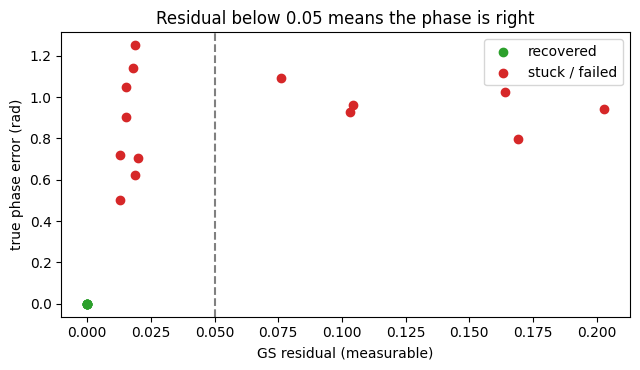

lab example: -695 ps/nm, 10 GBd -> ρ =   0.56 symbols of smear
lab example: -695 ps/nm, 28 GBd -> ρ =   4.37 symbols of smear
lab example: -695 ps/nm, 56 GBd -> ρ =  17.47 symbols of smear


In [6]:
import pandas as pd

def phase_rms(phi, truth):
    e = np.angle(np.exp(1j*(phi - truth)))
    return float(np.sqrt(np.mean(np.angle(np.exp(1j*(e - np.angle(np.mean(np.exp(1j*e))))))**2)))

sweep = []
for Dn in (5, 50, 500, 5000, 20000):
    for seed in range(4):
        sd = gs_core.make_measurements('QPSK', n_symbols=64, sps=8, snr_db=60, rng_seed=seed)
        E0 = sd['E']; J1 = np.abs(gs_core.disperse(E0, -Dn))**2; J2 = np.abs(gs_core.disperse(E0, -1.15*Dn))**2
        Ef = gs_field(J1, J2, -Dn, -1.15*Dn, 300)
        sweep.append(dict(D_norm=Dn, rho=Dn/64, seed=seed, residual=residual(Ef, J1, J2, -Dn, -1.15*Dn),
                          phase_err=phase_rms(np.angle(Ef), sd['phi_true'])))
sw = pd.DataFrame(sweep)
summary = sw.groupby('D_norm').agg(rho=('rho', 'first'), recovered=('phase_err', lambda x: f'{(x < 0.1).sum()}/{len(x)}'),
                                   median_phase_err=('phase_err', 'median'))
print(summary.round(3).to_string())

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ok = sw.phase_err < 0.1
ax.scatter(sw.residual[ok], sw.phase_err[ok], c='tab:green', label='recovered')
ax.scatter(sw.residual[~ok], sw.phase_err[~ok], c='tab:red', label='stuck / failed')
ax.axvline(0.05, ls='--', c='gray'); ax.set_xlabel('GS residual (measurable)'); ax.set_ylabel('true phase error (rad)')
ax.legend(); ax.set_title('Residual below 0.05 means the phase is right'); plt.tight_layout(); plt.show()

for Rs in (10, 28, 56):
    print(f'lab example: -695 ps/nm, {Rs} GBd -> ρ = {2*np.pi*phi2*(Rs*1e9)**2:6.2f} symbols of smear')

**Reading the sweep.**
* When dispersion smears only a few symbols (small ρ, typical of a single spool at 10–30 GBd), the two arms barely differ and GS doesn't recover the phase.
* With large ρ it either converges **exactly** or gets **stuck**, depending on the signal. The **residual separates the two cases**, which is why it's a pass condition in Section 5.

Ask the lab for the largest D difference they can provide, and report ρ alongside any result.

---
## 7. Self-test data: prove the pipeline before trusting a real result
This writes a synthetic QPSK pair to disk **in two lab-like formats** (a `.mat` with `I1`/`I2`, and two scope-style CSVs with header lines, a time offset between arms and a dark level). It then sends them through the same loader and validator as real data.

In [7]:
selftest_dir = WORK/'_selftest'; selftest_dir.mkdir(exist_ok=True)
sim = gs_core.make_measurements('QPSK', n_symbols=64, sps=8, D1=-5000.0, D2=-5750.0, snr_db=30, rng_seed=0)
spio.savemat(selftest_dir/'selftest_pair.mat', {'I1': sim['I1'], 'I2': sim['I2']})
t = np.arange(len(sim['I1']))/30e9
for k, (I, shift) in enumerate([(sim['I1'], 0), (sim['I2'], 37)], start=1):
    trace = np.roll(I, shift)*0.8 + 0.02                      # arm-2 delay, dark offset, scaling
    header = f'Model,DEMO-SCOPE\nChannel,CH{k}\nTime(s),Volts'
    np.savetxt(selftest_dir/f'selftest_CH{k}.csv', np.column_stack([t, trace]), delimiter=',', header=header, comments='')
(selftest_dir/'metadata.json').write_text(json.dumps({'D1': -5000, 'D2': -5750, 'D_units': 'norm',
                                                      'dark': [0.02, 0.02], 'constant_envelope': True}))
print('wrote', sorted(p.name for p in selftest_dir.iterdir()))

wrote ['metadata.json', 'selftest_CH1.csv', 'selftest_CH2.csv', 'selftest_pair.mat']


---
## 8. Run it
`run_pipeline()` = load → preprocess → null test (both sign conventions) → TD-GS → plots. It runs on **your uploaded files** if there are any, and on the self-test files otherwise.

[self-test] selftest_CH1.csv + selftest_CH2.csv | N = 512 | D_norm = -5,000.0, -5,750.0 | lag -41 -> -37
   energy ratio ΣI1/ΣI2         1.0023
   coarse lag (samples)         -41
   correlation(I1, I2)          0.4122
   PASS  finite
   PASS  not clipped (< 0.5% at max)
   PASS  energy ratio in [0.8, 1.25]
   PASS  converged (residual < 0.05)
   PASS  null test (ratio < 0.6)
   residual 0.0259; mismatched-pair residual 0.2535 (ratio 0.10)
   => TRUST this phase
   self-test phase error vs truth: 0.039 rad rms


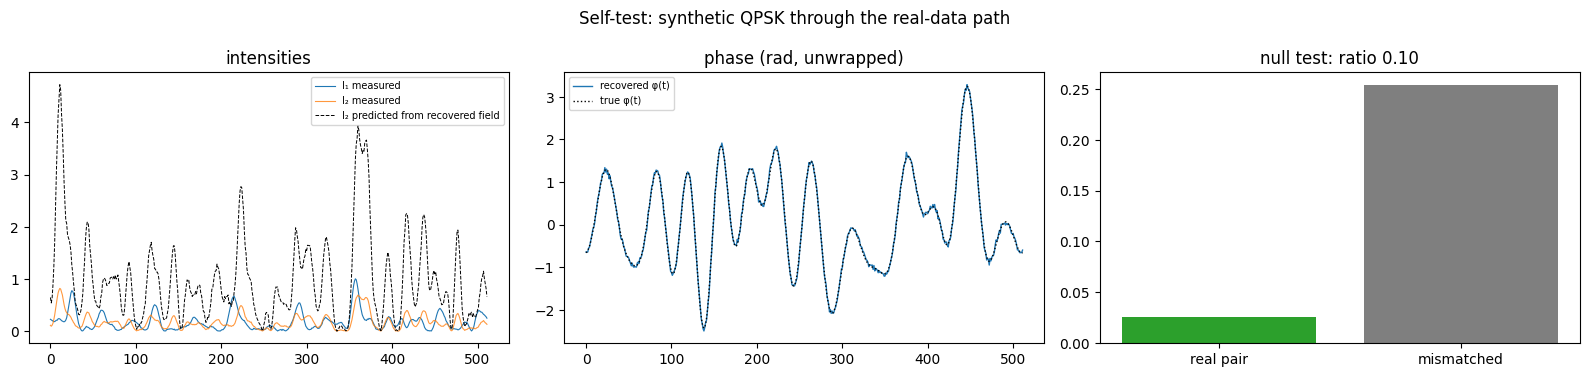

In [8]:
def run_pipeline(files, meta, n_iter=300, label=''):
    I1, I2, src = load_pair(files)
    I1, I2, lag0, checks, info = preprocess(I1, I2, dark=tuple(meta.get('dark', (0.0, 0.0))))
    u = meta.get('D_units', 'norm')
    D1 = to_norm(meta['D1'], u, meta.get('fs_GSps'), meta.get('lambda0_nm', 1550))
    D2 = to_norm(meta['D2'], u, meta.get('fs_GSps'), meta.get('lambda0_nm', 1550))
    kw = dict(unit_amplitude=bool(meta.get('constant_envelope', True)))
    lag = refine_lag(I1, I2, lag0, D1, D2, **kw)
    I2 = np.roll(I2, lag)
    E = gs_field(I1, I2, D1, D2, n_iter, **kw)
    res = residual(E, I1, I2, D1, D2)
    real, fake = null_test(I1, I2, D1, D2, n_iter=n_iter, **kw)
    checks['converged (residual < 0.05)'] = res < 0.05
    checks['null test (ratio < 0.6)'] = real/fake < 0.6
    print(f'[{label}] {src} | N = {len(I1)} | D_norm = {D1:,.1f}, {D2:,.1f} | lag {lag0} -> {lag}')
    for k, v in info.items():
        print(f'   {k:28s} {v}')
    for k, v in checks.items():
        print(f'   {"PASS" if v else "FAIL"}  {k}')
    print(f'   residual {res:.4f}; mismatched-pair residual {fake:.4f} (ratio {real/fake:.2f})')
    verdict = 'TRUST this phase' if all(checks.values()) else 'DO NOT trust this phase'
    print(f'   => {verdict}')
    return dict(I1=I1, I2=I2, E=E, phi=np.angle(E), D1=D1, D2=D2, checks=checks, info=info,
                residual=res, null=(real, fake), verdict=verdict)

def plot_result(r, title, phi_true=None):
    fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
    x = np.arange(len(r['I1']))
    ax[0].plot(x, r['I1'], lw=0.8, label='I₁ measured'); ax[0].plot(x, r['I2'], lw=0.8, label='I₂ measured', alpha=0.8)
    ax[0].plot(x, np.abs(gs_core.disperse(r['E'], r['D2']))**2, 'k--', lw=0.7, label='I₂ predicted from recovered field')
    ax[0].set_title('intensities'); ax[0].legend(fontsize=7)
    ax[1].plot(x, np.unwrap(r['phi']), lw=1, label='recovered φ(t)')
    if phi_true is not None:
        off = np.angle(np.mean(np.exp(1j*(r['phi'] - phi_true))))
        ax[1].plot(x, np.unwrap(phi_true + off), 'k:', lw=1, label='true φ(t)')
    ax[1].set_title('phase (rad, unwrapped)'); ax[1].legend(fontsize=7)
    real, fake = r['null']
    ax[2].bar(['real pair', 'mismatched'], [real, fake], color=['tab:green' if real/fake < 0.6 else 'tab:red', 'tab:gray'])
    ax[2].set_title(f"null test: ratio {real/fake:.2f}")
    fig.suptitle(title); plt.tight_layout(); plt.show()

# self-test, run through the two-CSV path (the harder one: headers, delay, dark level)
st = run_pipeline([selftest_dir/'selftest_CH1.csv', selftest_dir/'selftest_CH2.csv'],
                  load_metadata(selftest_dir), label='self-test')
print(f'   self-test phase error vs truth: {phase_rms(st["phi"], sim["phi_true"]):.3f} rad rms')
plot_result(st, 'Self-test: synthetic QPSK through the real-data path', phi_true=sim['phi_true'])

In [9]:
user_files = [p for p in DATA_FILES if p.name != 'metadata.json']
meta = load_metadata(WORK)
if user_files and meta:
    files = user_files if len(user_files) <= 2 else user_files[:2]
    out = run_pipeline(files, meta, label='your data')
    plot_result(out, f'Your data: {", ".join(p.name for p in files)}')
    np.savez(WORK/'recovered_phase.npz', phi=out['phi'], E=out['E'], I1=out['I1'], I2=out['I2'],
             D1=out['D1'], D2=out['D2'])
    (WORK/'recovered_report.json').write_text(json.dumps({**out['info'], **{k: bool(v) for k, v in out['checks'].items()},
                                                      'residual': out['residual'], 'verdict': out['verdict']}, indent=1))
    print('saved recovered_phase.npz and recovered_report.json to', WORK)
elif user_files:
    print('Found data files but no metadata.json. Add one with D1, D2 and units (template in Section 6).')
else:
    print('No uploaded data yet: the self-test above shows what a passing run looks like.')

No uploaded data yet: the self-test above shows what a passing run looks like.


### A cautionary example: the Dryad-derived pair
If `data/raw/raw_traces.npz` exists (it's made locally by `tools/import_dryad.py` and isn't in git), the next cell runs it through the same checks. Those two traces were pulled from **one** time-stretch **imaging** file, so there's no reason they should be one field at two dispersions. The checks should reject it, whatever D values we guess.

In [10]:
dryad = REPO/'data'/'raw'/'raw_traces.npz'
if dryad.exists():
    d = np.load(dryad)
    seg = slice(0, 4096)                                      # a manageable window of the 40,000-sample traces
    tmp = WORK/'_dryad_window.npz'; np.savez(tmp, I1=d['i1'][seg], I2=d['i2'][seg])
    for guess in (-5000, -20000):
        r = run_pipeline([tmp], {'D1': guess, 'D2': guess*1.15, 'D_units': 'norm', 'constant_envelope': False},
                         label=f'Dryad pair, D guess {guess}')
    tmp.unlink()
else:
    print('data/raw/raw_traces.npz not present (expected in Colab); skipping.')

[Dryad pair, D guess -5000] _dryad_window.npz:I1/I2 | N = 4096 | D_norm = -5,000.0, -5,750.0 | lag 0 -> 6
   energy ratio ΣI1/ΣI2         0.1007
   coarse lag (samples)         0
   correlation(I1, I2)          0.7826
   PASS  finite
   PASS  not clipped (< 0.5% at max)
   FAIL  energy ratio in [0.8, 1.25]
   FAIL  converged (residual < 0.05)
   FAIL  null test (ratio < 0.6)
   residual 0.1064; mismatched-pair residual 0.1489 (ratio 0.71)
   => DO NOT trust this phase


[Dryad pair, D guess -20000] _dryad_window.npz:I1/I2 | N = 4096 | D_norm = -20,000.0, -23,000.0 | lag 0 -> -4
   energy ratio ΣI1/ΣI2         0.1007
   coarse lag (samples)         0
   correlation(I1, I2)          0.7826
   PASS  finite
   PASS  not clipped (< 0.5% at max)
   FAIL  energy ratio in [0.8, 1.25]
   PASS  converged (residual < 0.05)
   FAIL  null test (ratio < 0.6)
   residual 0.0119; mismatched-pair residual 0.0127 (ratio 0.94)
   => DO NOT trust this phase


**Why both checks are needed.** With a very large assumed D, GS can drive the residual low on almost any pair, because it has enough freedom to fit noise. The null test catches this: a mismatched pair fits just as well (ratio ≈ 1), so a low residual on its own proves nothing. Together with the energy check, a real pair has to pass all three.

---
## What to send the lab, and what "done" looks like
The project is finished when a **real** pair:
1. passes every check in Section 5 (energy, convergence, null test),
2. reports its ρ (dispersion in symbols) from Section 6, and
3. with a known-input run, recovers the phase to a stated rms error, which also settles the φ/−φ sign.

If you ask for one thing, ask for **a known-input QPSK run: I₁, I₂, D₁, D₂, sample rate and wavelength.** Then run this notebook, attach `recovered_report.json` and the figure to your reply, and the loop is closed.

**References:** Solli, Gupta & Jalali, *Appl. Phys. Lett.* 95, 231108 (2009) · Gerchberg & Saxton, *Optik* 35, 237 (1972) · Kolner, *IEEE J. Quantum Electron.* 30, 1951 (1994) · Chen, Mahjoubfar & Jalali, *PLOS ONE* (2015), data at Dryad 10.5061/dryad.2h7d2.